In [1]:
#Project statement:
#AAL, established in 2000, is a well-known brand in Australia, particularly recognized for its clothing business. It has opened branches in various states, metropolises, and tier-1 and tier-2 cities across the country.
#The brand caters to all age groups, from kids to the elderly.
#Currently experiencing a surge in business, AAL is actively pursuing expansion opportunities. To facilitate informed investment decisions, the CEO has assigned the responsibility to the head of AAL’s sales and marketing (S&M) department. The specific tasks include:
#1)	Identify the states that are generating the highest revenues.
#2)	Develop sales programs for states with lower revenues. The head of sales and marketing has requested your assistance with this task.
#Analyze the sales data of the company for the fourth quarter in Australia, examining it on a state-by-state basis. Provide insights to assist the company in making data-driven decisions for the upcoming year.
#As a data scientist, you must perform the following steps on the enclosed data:
#   1.	Data wrangling
#   2.	Data analysis
#   3.	Data visualization
#   4.	Report generation


In [10]:
#1.	Data wrangling
#   a.	Ensure that the data is clean and free from any missing or incorrect entries.
#       ○	Inspect the data manually to identify missing or incorrect information using the functions isna() and notna().
#   b.	Based on your knowledge of data analytics, include your recommendations for treating missing and incorrect data (dropping the null values or filling them).
#   c.	Choose a suitable data wrangling technique—either data standardization or normalization. Execute the preferred normalization method and present the resulting data. (Normalization is the preferred approach for this problem.)
#   d.	Share your insights regarding the application of the GroupBy() function for either data chunking or merging, and offer a recommendation based on your analysis.

import pandas as pd
import numpy as np

# Load dataset
print("Step-1: Loading dataset...")
data = pd.read_csv("datasets/AusApparalSales4thQrt2020.csv")
print("Dataset loaded successfully.")
# Display first few rows
print("First few rows of the dataset:")
print(data.head())

# Dataset information
print("\nDataset Info:")
data.info()

# Check dimensions
print("\nShape:", data.shape)
print("========================================================================================")
print("Step1a: Checking for missing values...")
print("\nMissing Values per Column:")
print(data.isna().sum())

# Check non-missing values
print("\nNon-Missing Values per Column:")
print(data.notna().sum())

# Total missing values
print("\nTotal Missing Values:")
print(data.isna().sum().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("========================================================================================")
print("Step1b: Handling missing values...")
# Assuming we will fill missing values with the mean for numerical columns and mode for categorical columns
if data.isna().sum().sum() == 0:
    print("Dataset contains no missing values.")
else:
    print("Missing values detected.")

print("========================================================================================")
print("Step1c: Normalizing the data...")
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Numerical columns only

numeric_cols = data.select_dtypes(include=np.number).columns

data_normalized = data.copy()

data_normalized[numeric_cols] = scaler.fit_transform(
    data[numeric_cols]
)

print(data_normalized.head())
print(
    data_normalized[numeric_cols].describe()
)

print("========================================================================================")
print("Step1d: Applying GroupBy function...")
state_sales = data.groupby(
    "State"
)["Sales"].sum()

print("StateWise Sales:",state_sales)

group_sales = data.groupby(
    "Group"
)["Sales"].sum()

print("GroupWise Sales:",group_sales)

state_group_sales = data.groupby(
    ["State", "Group"]
)["Sales"].sum()

print("StateGroupWise Sales:",state_group_sales)

Step-1: Loading dataset...
Dataset loaded successfully.
First few rows of the dataset:
         Date        Time State     Group  Unit  Sales
0  1-Oct-2020     Morning    WA      Kids     8  20000
1  1-Oct-2020     Morning    WA       Men     8  20000
2  1-Oct-2020     Morning    WA     Women     4  10000
3  1-Oct-2020     Morning    WA   Seniors    15  37500
4  1-Oct-2020   Afternoon    WA      Kids     3   7500

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB

Shape: (7560, 6)
Step1a: Checking for missing values...

Missing Values per Column:
Date     0
Time     0
State    0
Grou

In [ ]:
#2.	Data analysis
#   a.	Perform descriptive statistical analysis on the data in the Sales and Unit columns. Utilize techniques such as mean, median, mode, and standard deviation for this analysis.
#   b.	Identify the group with the highest sales and the group with the lowest sales based on the data provided.
#   c.	Identify the group with the highest and lowest sales based on the data provided.
#   d.	Generate weekly, monthly, and quarterly reports to document and present the results of the analysis conducted.
#   (Use suitable libraries such as NumPy, Pandas, and SciPy for performing the analysis.)
print("========================================================================================")
print("Step-2a: Descriptive statistical analysis for Sales and Units...")
print("\nDescriptive Statistics for Sales:")
import pandas as pd
import numpy as np

# Descriptive statistics for Sales
print(data[["Sales", "Unit"]].describe())

print("========================================================================================")
print("Step-2b: Identifying groups with highest and lowest sales...")
print("Aggregated sales by Group:")
group_sales = data.groupby(
    "Group"
)["Sales"].sum()

print(group_sales)

print("\nHighest sales group")
highest_group = group_sales.idxmax()
highest_sales = group_sales.max()
print("Highest Sales Group:", highest_group)
print("Sales:", highest_sales)

print("\nLowest sales group")
lowest_group = group_sales.idxmin()
lowest_sales = group_sales.min()
print("Lowest Sales Group:", lowest_group)
print("Sales:", lowest_sales)

print("========================================================================================")
print("Step-2c: Identifying states with highest and lowest sales...")
group_sales_sorted = group_sales.sort_values(
    ascending=False
)

print(group_sales_sorted)
print(
    "\nTop Performing Group:",
    group_sales_sorted.index[0]
)
print(
    "Lowest Performing Group:",
    group_sales_sorted.index[-1]
)

print("========================================================================================")
print("Step-2d: Generating weekly, monthly, and quarterly reports...")
print("Weekly Sales Report:")
data["Date"] = pd.to_datetime(
    data["Date"]
)
weekly_report = data.groupby(
    pd.Grouper(
        key="Date",
        freq="W"
    )
).agg({
    "Sales":"sum",
    "Unit":"sum"
})
print(weekly_report)

print("\nMonthly Sales Report:")
monthly_report = data.groupby(
    pd.Grouper(
        key="Date",
        freq="ME"
    )
).agg({
    "Sales":"sum",
    "Unit":"sum"
})
print(monthly_report)

print("\nQuarterly Sales Report:")
quarterly_report = data.groupby(
    pd.Grouper(
        key="Date",
        freq="QE"
    )
).agg({
    "Sales":"sum",
    "Unit":"sum"
})

print(quarterly_report)

Step-2a: Descriptive statistical analysis for Sales and Units...

Descriptive Statistics for Sales:
               Sales         Unit
count    7560.000000  7560.000000
mean    45013.558201    18.005423
std     32253.506944    12.901403
min      5000.000000     2.000000
25%     20000.000000     8.000000
50%     35000.000000    14.000000
75%     65000.000000    26.000000
max    162500.000000    65.000000
Step-2b: Identifying groups with highest and lowest sales...
Aggregated sales by Group:
Group
Kids       85072500
Men        85750000
Seniors    84037500
Women      85442500
Name: Sales, dtype: int64

Highest sales group
Highest Sales Group:  Men
Sales: 85750000

Lowest sales group
Lowest Sales Group:  Seniors
Sales: 84037500
Step-2c: Identifying states with highest and lowest sales...
Group
Men        85750000
Women      85442500
Kids       85072500
Seniors    84037500
Name: Sales, dtype: int64

Top Performing Group:  Men
Lowest Performing Group:  Seniors
Step-2d: Generating weekly, mon

Step3a: Creating visualizations for the dashboard...
1. State-wise sales analysis for different demographic groups...


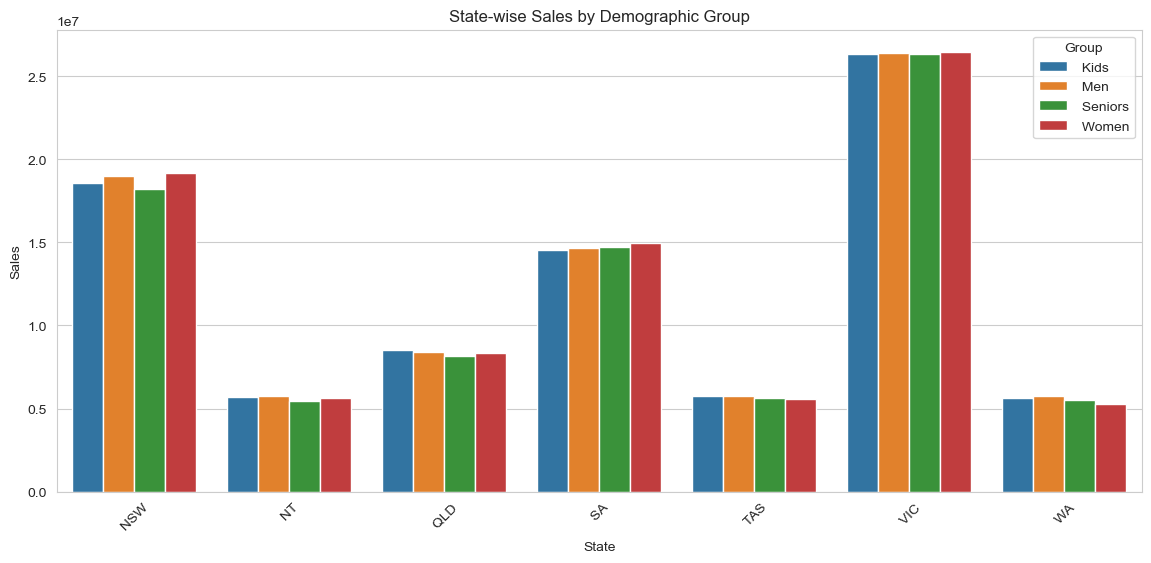

2. Group-wise sales analysis across various states...


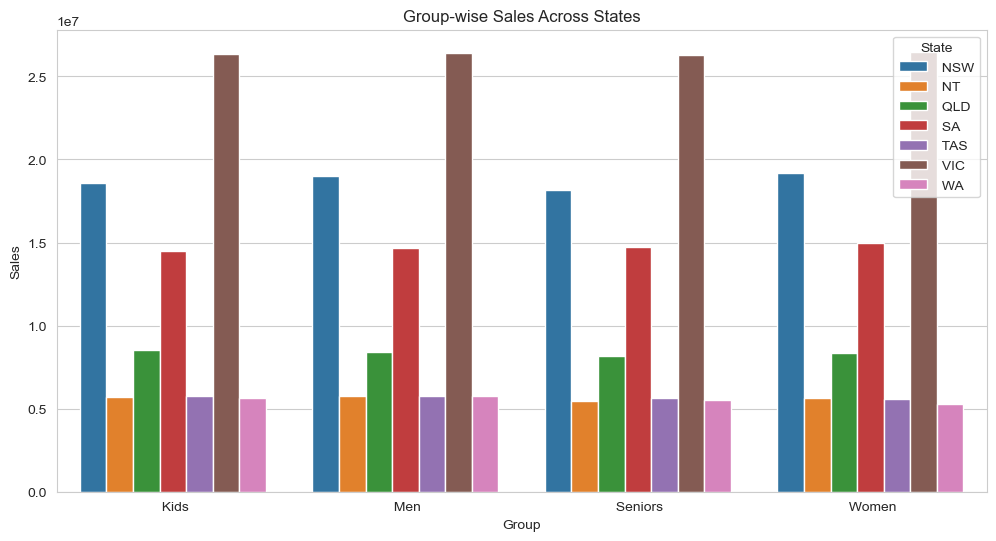

3. Time-of-the-day analysis for peak and off-peak sales periods...


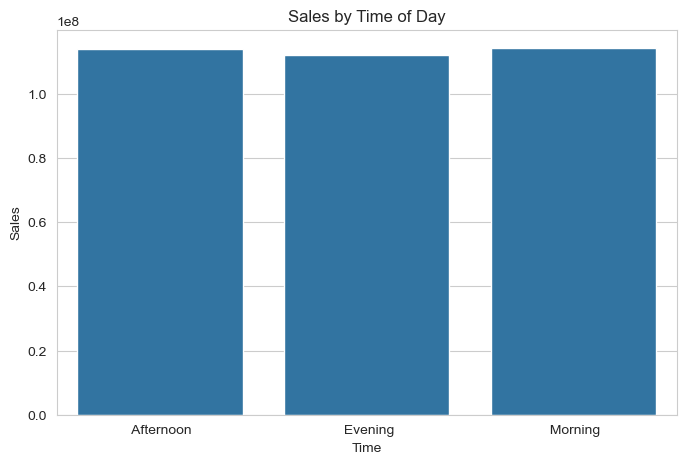

Peak Sales Period:
Time       Morning
Sales    114207500
Name: 2, dtype: object

Off-Peak Sales Period:
Time       Evening
Sales    112087500
Name: 1, dtype: object
Step3b: Ensuring clear and accessible visualization for decision-making...
Daily Sales Trend:


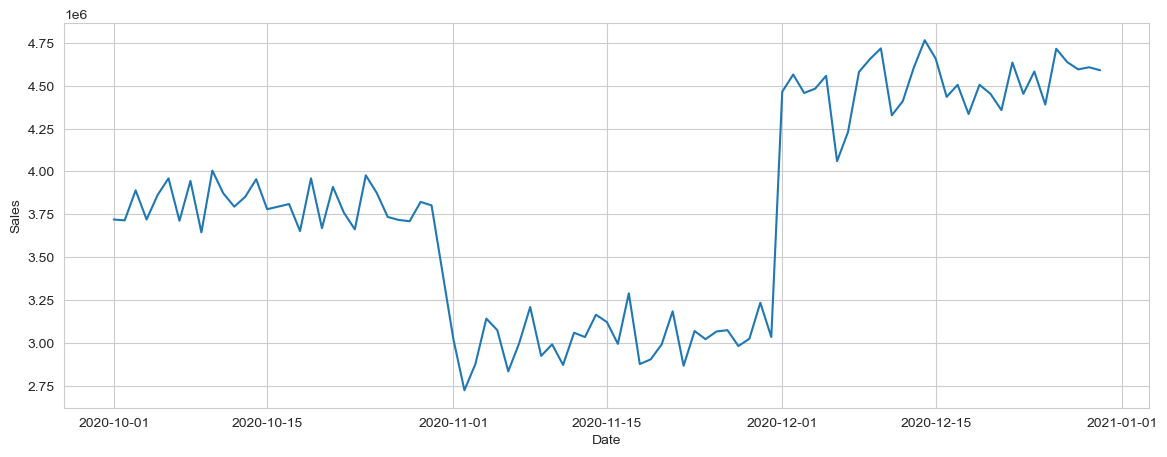


Weekly Sales Trend:


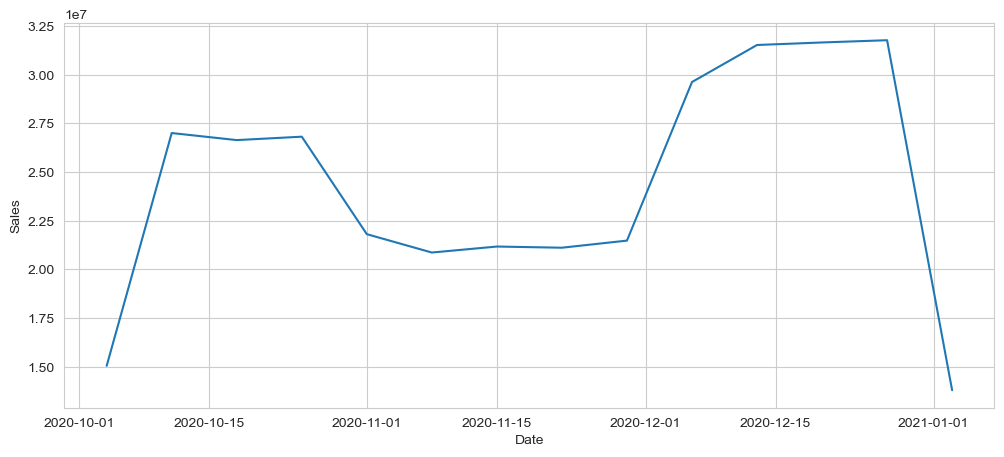


Monthly Sales Trend:


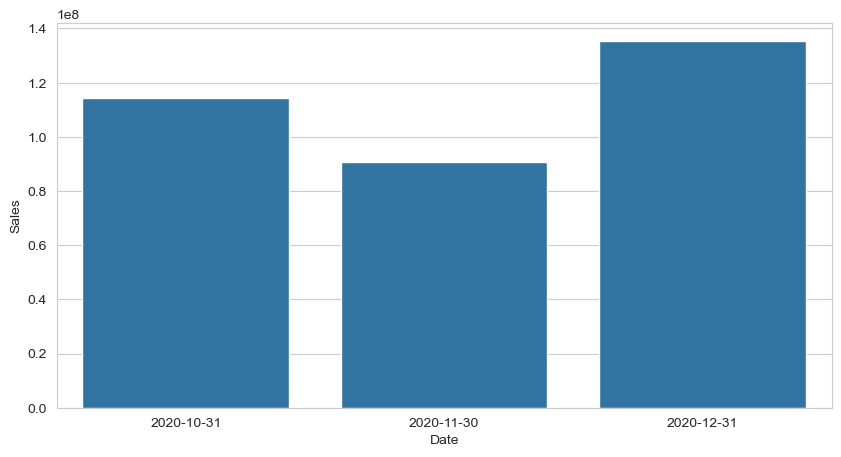


Quarterly Sales Trend:


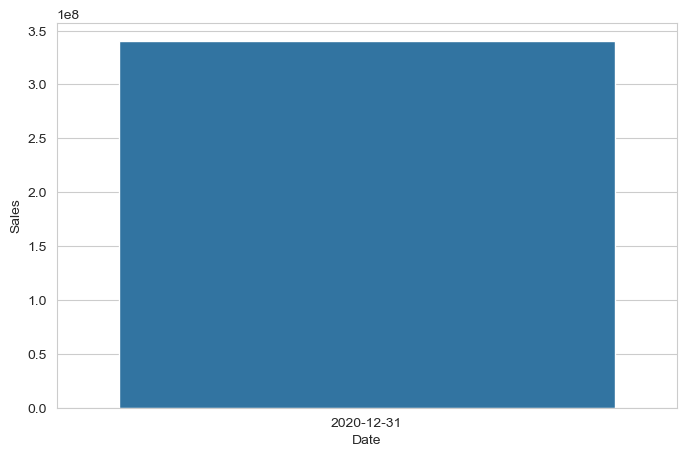

Step3c: Recommendation for visualization package...


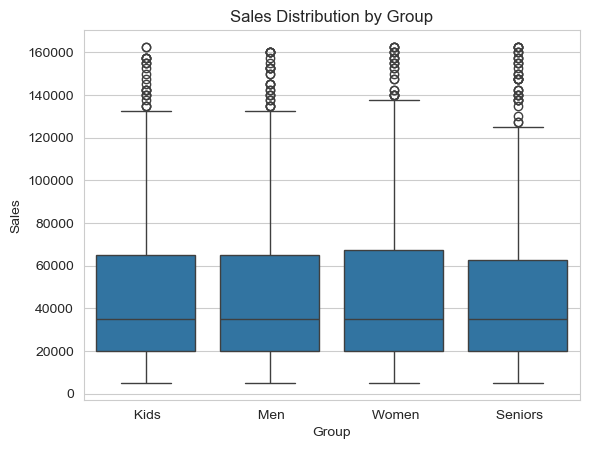

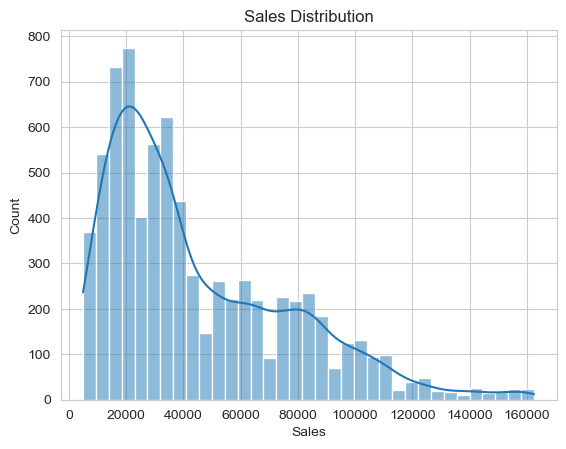

In [42]:
#3.	Data visualization
#   a.	Use suitable data visualization libraries to construct a dashboard for the head of sales and marketing. The dashboard should encompass key parameters:
#       o	State-wise sales analysis for different demographic groups (kids, women, men, and seniors).
#       o	Group-wise sales analysis (Kids, Women, Men, and Seniors) across various states.
#       o	Time-of-the-day analysis: Identify peak and off-peak sales periods to facilitate strategic planning for S&M teams. This information aids in designing programs like hyper-personalization and Next Best Offers to enhance sales.
#   b.	Ensure the visualization is clear and accessible for effective decision-making by the head of sales and marketing (S&M).
#   The dashboard must contain daily, weekly, monthly, and quarterly charts.
#   (Any visualization library can be used for this purpose. However, since statistical analysis is being done, Seaborn is preferred.)
#   c.	Include your recommendation and indicate why you are choosing the recommended visualization package.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Convert Date column
data["Date"] = pd.to_datetime(data["Date"])

# Create Day Name
data["Day"] = data["Date"].dt.day_name()

# Create Month
data["Month"] = data["Date"].dt.month_name()

# Create Quarter
data["Quarter"] = data["Date"].dt.quarter

print("Step3a: Creating visualizations for the dashboard...")
print("1. State-wise sales analysis for different demographic groups...")
plt.figure(figsize=(14,6))

state_group_sales = data.groupby(
    ["State","Group"]
)["Sales"].sum().reset_index()

sns.barplot(
    data=state_group_sales,
    x="State",
    y="Sales",
    hue="Group"
)

plt.title(
    "State-wise Sales by Demographic Group"
)

plt.xticks(rotation=45)

plt.show()

print("=========================================================================================")
print("2. Group-wise sales analysis across various states...")
plt.figure(figsize=(12,6))

group_state_sales = data.groupby(
    ["Group","State"]
)["Sales"].sum().reset_index()
sns.barplot(
    data=group_state_sales,
    x="Group",
    y="Sales",
    hue="State"
)
plt.title(
    "Group-wise Sales Across States"
)
plt.show()

print("=========================================================================================")
print("3. Time-of-the-day analysis for peak and off-peak sales periods...")
plt.figure(figsize=(8,5))

time_sales = data.groupby(
    "Time"
)["Sales"].sum().reset_index()

sns.barplot(
    data=time_sales,
    x="Time",
    y="Sales"
)

plt.title(
    "Sales by Time of Day"
)

plt.show()

peak_period = time_sales.loc[
    time_sales["Sales"].idxmax()
]

off_peak_period = time_sales.loc[
    time_sales["Sales"].idxmin()
]

print("Peak Sales Period:")
print(peak_period)

print("\nOff-Peak Sales Period:")
print(off_peak_period)

print("=========================================================================================")
print("Step3b: Ensuring clear and accessible visualization for decision-making...")
print("Daily Sales Trend:")
daily_sales = data.groupby(
    "Date"
)["Sales"].sum().reset_index()

plt.figure(figsize=(14,5))
sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Sales"
)
plt.show()

print("\nWeekly Sales Trend:")
weekly_sales = data.groupby(
    pd.Grouper(
        key="Date",
        freq="W"
    )
)["Sales"].sum().reset_index()
plt.figure(figsize=(12,5))
sns.lineplot(
    data=weekly_sales,
    x="Date",
    y="Sales"
)
plt.show()

print("\nMonthly Sales Trend:")
monthly_sales = data.groupby(
    pd.Grouper(
        key="Date",
        freq="ME"
    )
)["Sales"].sum().reset_index()
plt.figure(figsize=(10,5))
sns.barplot(
    data=monthly_sales,
    x="Date",
    y="Sales"
)
plt.show()

print("\nQuarterly Sales Trend:")
quarterly_sales = data.groupby(
    pd.Grouper(
        key="Date",
        freq="QE"
    )
)["Sales"].sum().reset_index()
plt.figure(figsize=(8,5))
sns.barplot(
    data=quarterly_sales,
    x="Date",
    y="Sales"
)
plt.show()

print("=========================================================================================")
print("Step3c: Recommendation for visualization package...")
sns.boxplot(data=data, x="Group", y="Sales")
plt.title("Sales Distribution by Group")
plt.show()

sns.histplot(data["Sales"], kde=True)
plt.title("Sales Distribution")
plt.show()

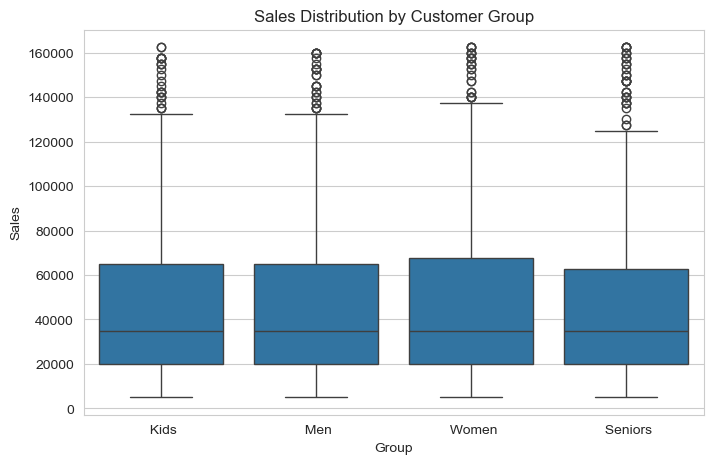

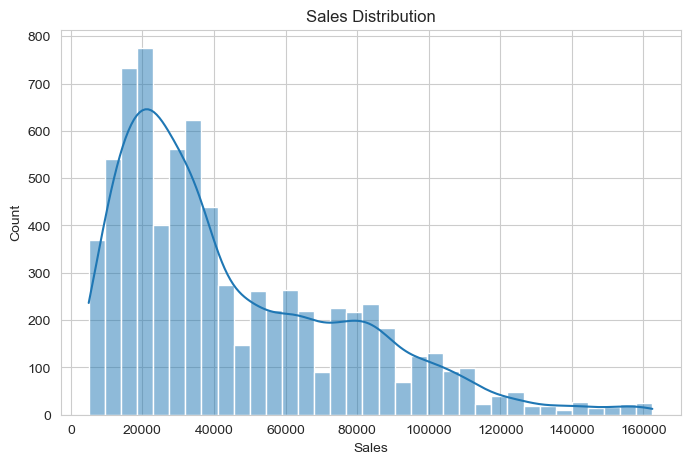

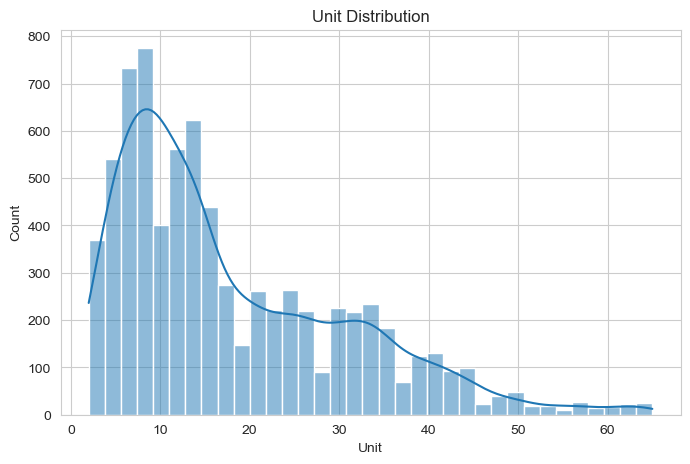

In [45]:
#4.	Report generation 
#   a)	Use JupyterLab Notebook for generating reports, which includes tasks such as data wrangling, analysis, and visualization. Please note that JupyterLab enables you to integrate code seamlessly with graphs and plots.
#   b)	Use Markdown in suitable places while presenting your report. 
#   c)	Use suitable graphs, plots, and analysis reports in the report, along with recommendations. Note that various aspects of analysis require different graphs and plots.
#       ○	Use a box plot for descriptive statistics.
#       ○	Use the Seaborn distribution plot for any other statistical plotting.

# Boxplot for descriptive statistics
plt.figure(figsize=(8,5))
sns.boxplot(
    data=data,
    x="Group",
    y="Sales"
)
plt.title("Sales Distribution by Customer Group")
plt.show()

# seaborn distribution plot for sales distribution
plt.figure(figsize=(8,5))
sns.histplot(
    data["Sales"],
    kde=True
)
plt.title("Sales Distribution")
plt.show()

#unit distribution
plt.figure(figsize=(8,5))
sns.histplot(
    data["Unit"],
    kde=True
)
plt.title("Unit Distribution")
plt.show()